In [1]:
#Packages needed for the notebook
using CSV #to read CSV files
using Serialization #To write or read file ".bin"
using Revise #To include julia files with functions needed to run the notebook
using LinearAlgebra #For linear algebra operations
using ReverseDiff #To perform gradient computaiton
using Random #To extract random numbers
using PyPlot #To plot results
using NaNStatistics #To make avareges over windows
using Statistics #For mean values 
using LsqFit

### Including Files

In [2]:
function correct_path(splitted_path, String)
    S=""
    for i in 1:(length(splitted_path)-1)
        S=S*splitted_path[i]*"/"
    end
    return S*String 
end

correct_path (generic function with 1 method)

In [3]:
#Including files with the functions
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets

### Datasets

In [4]:
#Importing, training, test and prior datasets
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
test=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Test1_GLORI.bin")) 
prior_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_GLORI.bin")); 

In [5]:
#Saving all the gene labels for the three datasets
gene_train=keys(train);
gene_test=keys(test);
gene_prior=keys(prior_HEK);

### Trained models

In [6]:
#Importing models trained on GLORI HEK293T
M5=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin")) # p(s̄|m)
M6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin")); # p(s̄|m̄)

### Distibution of motives (train-set):

In [7]:
#Computing distribution of m6A and A over coding transcripts
bin=collect(0:0.001:1);
avarege_window=20
x_met, y_met=avarege_distribution(train, gene_train, avarege_window, bin; label=1)
x_not, y_not=avarege_distribution(train, gene_train, avarege_window, bin, label=0);

## Test:

In [8]:
#To test genes I only keep those transcripts for which a proxy of the methylation abundancy is knwon
common_genes=intersect(vcat(gene_prior...),vcat(gene_test...)) # T̃ ∩ T 
genes_not=filtering_non_nucelotides(test)
#Removing a gene with non canonical nucleotide letterse
common_genes=setdiff(common_genes, genes_not); # T̃ ∩ T \ T_n 

In [9]:
#Mapping all coding transcripts into a sequnence of 33% 5'-UTR, 33% CDS, 33% 3'-UTR
MAP=mapping_position(test, common_genes);

### Baseline DRACH model

In [10]:
#Creating all test sets over coding transcripts
test_met, ratio_test , gene_test_met , test_not , gene_test_not =crete_set_all(test, (keys(MAP)));

$$p_{BaselineDRACH}(m|\vec{s})=\begin{cases} 1 \ \ \ \ \ if \ \vec{s}\in DRACH \\0 \ \ \ \ \  otherwise \end{cases}$$

In [11]:
#Numerical translation of the previous equation
N_met_a=[null_model(test_met[i]) for i in 1:length(test_met)];
N_not_a=[null_model(test_not[i]) for i in 1:length(test_not)];
#Computing the PCR point and the F1 score
x,y=sum(N_met_a)/length(N_met_a) ,sum(N_met_a)/(sum(N_met_a)+sum(N_not_a)) 
F1=2 .* (y.*x)./(y.+x); 
#ROC point 
x_R,y_R=sum(N_not_a)/length(N_not_a) , sum(N_met_a)/length(N_met_a);

### 1. MEMAR-C: Constant prior
$p(m|\vec{s})\propto p(\vec{s}|m)\cdot p_0(m) \ \ \ where \ \ \  p_0(m)= \frac{1}{\mathcal{N}_\mathcal{T}}\sum_{i=1}^{\mathcal{N}_\mathcal{T}} \frac{N^{T'_i}_{m^6A}}{N^{T'_i}_{m^6A}+N^{T'_i}_A}=\langle p_0^{T'}(m)\rangle_{T'}$

In [12]:
#Unifor prior definition following the previous equation
Ava=[]
[push!(Ava, train[a].perc_met) for a in gene_train];
Ava=mean(Ava)
constant_prior=deepcopy(test)
[constant_prior[a].perc_met=Ava for a in keys(test)];

In [13]:
score_met_ps,score_not_met_ps=score_ps_ds_pm(M5, M6, test, keys(MAP), constant_prior);

In [14]:
#Computing the treshold value above which motifs are predicted by MEMAR as mehtylated
_,tr1=plot_PR_score(vcat(score_met_ps...), vcat(score_not_met_ps...),  "palevioletred",L"p(\vec{s}|m)\cdot p_0(m)"; xx=-0.02, pas=0.005,ls="-", mark="o");

In [15]:
#Scoring all the 8-mers
score_8mers=score_8_mers(M5, M6, Ava/100);

In [16]:
#Dictionary with all 8-mers which are above the tresholds
mots_8=mots_list8[findall(x->x>=tr1, score_8mers )]
Dict_8=Dict()
#Finding all DRACH motifs that at least once appear inside the set of 8-mers methylated motifs
[(haskey(Dict_8, i[3:4]*'A'*i[5:6])==true ? nothing : Dict_8[i[3:4]*'A'*i[5:6]]=[]) for i in mots_8 ];

In [17]:
println("Percentage of 8-mers methylated following MEMAR with uniform prior: $(length(mots_8)/4^8*100)")
println("Percentage of 5-mers methylated following null DRACH model: $(18/4^4*100)")

Percentage of 8-mers methylated following MEMAR with uniform prior: 1.21307373046875
Percentage of 5-mers methylated following null DRACH model: 7.03125


### 2. MEMAR-XC: Modulated distance with constant prior
$p(m|\vec{s})\propto p(\vec{s}|m)\cdot d(x_T(\vec{s})|m) \cdot p_0(m)$

In [18]:
score_met_ps_ds,score_not_met_ps_ds=score_ps_ds_pm(M5, M6,  test, keys(MAP), constant_prior; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not]);
_,tr2=plot_PR_score(vcat(score_met_ps_ds...), vcat(score_not_met_ps_ds...),  "cornflowerblue",L"p(\vec{s}_T|m) \cdot d(x(\vec{s}_T|m)\cdot p_0(m)"; xx=-0.02,pas=0.005, ls="-", mark="s")

(Figure(PyObject <Figure size 640x480 with 1 Axes>), 0.21)

###  3. MEMAR-T: Transcript-dependent Prior
$p(m|\vec{s})\propto p(\vec{s}|m) \cdot p_0^T(m) \ \ \ where \ \ \ p_0^{T_j}(m)=\frac{\langle p_0^{T'}(m)\rangle_{T'}}{\langle p_0^{\tilde{T}}(m)\rangle_{\tilde{T}}}p_0^{\tilde{T}_j}(m) $

In [19]:
# Transcript-dependent prior following the above equation
P=[]
[push!(P, prior_HEK[a].perc_met) for a in keys(prior_HEK)]
[prior_HEK[a].perc_met=Ava/mean(P).*prior_HEK[a].perc_met for a in keys(prior_HEK)];

In [20]:
score_met_ps_pm,score_not_met_ps_pm=score_ps_ds_pm(M5, M6, test, keys(MAP), prior_HEK);
_,tr3=plot_PR_score(vcat(score_met_ps_pm...), vcat(score_not_met_ps_pm...),  "lightseagreen",L"p(\vec{s}_T|m)\cdot p_0^T(m)"; xx=0, pas=0.005,ls="-", mark="v")

(Figure(PyObject <Figure size 640x480 with 1 Axes>), 0.225)

### 4. MEMAR-XT: Modulated distant with non-uniform prior
$p(m|\vec{s}) \propto p(\vec{s}|m) d(x_T(\vec{s})|m)\cdot p_0^T(m)$

In [21]:
score_met_ps_ds_pm,score_not_met_ps_ds_pm=score_ps_ds_pm(M5, M6, test, keys(MAP), prior_HEK; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not]);
_,tr4=plot_PR_score(vcat(score_met_ps_ds_pm...), vcat(score_not_met_ps_ds_pm...),  "goldenrod",L"p(\vec{s}_T|m)\cdot d(x(\vec{s}_T|m)\cdot p_0^T(m)"; xx=0.02,pas=0.005, ls="-", mark="*");

### Distance non-methylated sites

Computing the predicted distirbution of non-methylated motifs. Sites with lower probability to the treshold for each MEMAR class are retained and projected into a metagene profile of 1/3 5'-UTR,  1/3 CDS and 1/3 3'-UTR. 

#### MEMAR-C

In [22]:
dist_met_pred_ps=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, Ava/100, test[label].sequence, 8; verbose=false)
    v=intersect(findall(x->x=='A', test[label].sequence), findall(x->x<tr1, S))
    push!(dist_met_pred_ps, MAP[label][v]) 
end

#### MEMAR-XC

In [23]:
dist_met_pred_ps_ds=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, Ava/100, test[label].sequence, 8;  verbose=true, Mapping=MAP, dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=label)
    v=intersect(findall(x->x=='A', test[label].sequence), findall(x->x<tr2, S))
    push!(dist_met_pred_ps_ds, MAP[label][v]) 
end

#### MEMAR-T

In [24]:
dist_met_pred_ps_pm=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, prior_HEK[label].perc_met/100, test[label].sequence, 8; verbose=false)
    v=intersect(findall(x->x=='A', test[label].sequence), findall(x->x<tr3, S))
    push!(dist_met_pred_ps_pm, MAP[label][v]) 
end

#### MEMAR-XT

In [25]:
dist_met_pred_ps_ds_pm=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, prior_HEK[label].perc_met/100, test[label].sequence, 8;  verbose=true, Mapping=MAP, dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=label)
    v=intersect(findall(x->x=='A', test[label].sequence), findall(x->x<tr4, S))
    push!(dist_met_pred_ps_ds_pm, MAP[label][v]) 
end

#### Baseline DRACH model

In [26]:
mers5A=[mots_list4[i][1:2]*"A"*mots_list4[i][3:4] for i in 1:length(mots_list4)];
DRACH=["TAACA", "AAACA", "GAACA", "TGACA", "AGACA", "GGACA", "TAACC", "AAACC", "GAACC", "TGACC", "AGACC", "GGACC", "TAACT", "AAACT", "GAACT", "TGACT", "AGACT", "GGACT"];
list_nonDRACH=setdiff!(mers5A, DRACH)
dist_DRACH=[]
for label in keys(MAP)
    temp=vcat([findall(a, test[label].sequence) for a in list_nonDRACH]...)
    pos=[temp[i][3] for i in 1:length(temp)]
    push!(dist_DRACH, MAP[label][sort(pos)]) 
end

In [27]:
#Computing the same dsitribution form experimental methylated sites
x_not_met_ref, y_not_met_ref=avarege_distribution(test, gene_test, avarege_window, bin;label=0);

In [28]:
#Computing the density distirbution in the metagene profile
yy_1, xx_1=hist(vcat(dist_met_pred_ps...), histtype="step" ,bins=bin, density=true, color="palevioletred",alpha=0.4);
yy_2, xx_2=hist(vcat(dist_met_pred_ps_ds...), histtype="step" ,bins=bin, density=true, color="yellowgreen",alpha=0.4);
yy_3, xx_3=hist(vcat(dist_met_pred_ps_pm...), histtype="step" ,bins=bin, density=true, color="lightseagreen",alpha=0.4);
yy_4, xx_4=hist(vcat(dist_met_pred_ps_ds_pm...), histtype="step" ,bins=bin, density=true, color="goldenrod",alpha=0.4);
yy_D, xx_D=hist(vcat(dist_DRACH...), histtype="step" ,bins=bin, density=true, color="lightgrey",alpha=0.4);

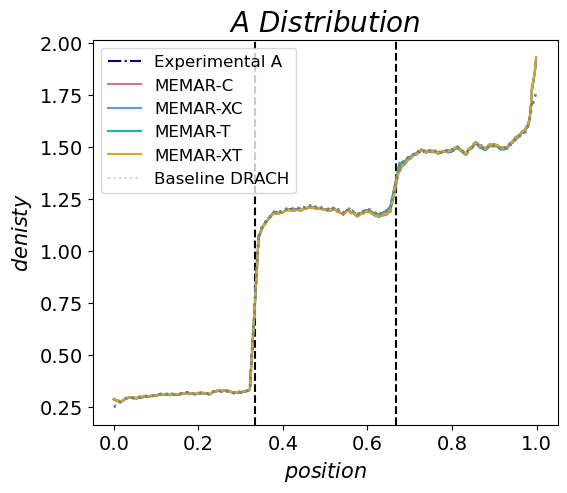

In [29]:
close("all")
figure(figsize=(6, 5))
#plotting each results:
plot(x_not_met_ref, y_not_met_ref, color="navy", ls="-.",label="Experimental A")
plot(xx_1[1:end-1], movmean(yy_1, avarege_window), color="palevioletred")
plot(xx_2[1:end-1], movmean(yy_2, avarege_window), color="cornflowerblue")
plot(xx_3[1:end-1], movmean(yy_3, avarege_window), color="lightseagreen")
plot(xx_4[1:end-1], movmean(yy_4, avarege_window), color="goldenrod")
plot(xx_D[1:end-1], movmean(yy_D, avarege_window), color="grey", ls=":", lw=2)
axvline(x=1/3, color="black", linestyle="--", zorder=1)
axvline(x=2/3, color="black", linestyle="--", zorder=1)
#Legend
plot(1, 1, label="MEMAR-C",color="palevioletred")
plot(1, 1, label="MEMAR-XC",color="cornflowerblue")
plot(1, 1, label="MEMAR-T",color="lightseagreen")
plot(1, 1, label="MEMAR-XT",color="goldenrod")
plot(1, 1, label="Baseline DRACH",ls=":",color="lightgrey")
title(L"A \ Distribution", size=20)
ylabel(L"denisty", size=15)
xlabel(L"position", size=15)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
gcf()

### Changin motifs size, from 4 to 16:

Creating the corresponding training and testing sets at different motifs sizes:

In [30]:
train_met4, ratio_train4, _, train_not4, _=crete_set_all(train, gene_train; window=2);
train_met6, ratio_train6, _, train_not6, _=crete_set_all(train, gene_train; window=3);
train_met10, ratio_train10, _, train_not10, _=crete_set_all(train, gene_train; window=5);
train_met12, ratio_train12, _, train_not12, _=crete_set_all(train, gene_train; window=6);
train_met14, ratio_train14, _, train_not14, _=crete_set_all(train, gene_train; window=7);
train_met16, ratio_train16, _, train_not16, _=crete_set_all(train, gene_train; window=8);

### Training models at different motifs size

In [31]:
Indexes=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Index_train_not.bin"));

#### 4-mers:

In [32]:
#Training the methylated dataset
M1=strucutre_model(train_met4 , parse.(Float64,ratio_train4) ; Lseq=4, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001)
#Training the non-methylated dataset
M2=strucutre_model(train_not4[Indexes], vcat(ones(1,length(Indexes ))...); Lseq=4, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001)  

Converged at iteration 227, where the maximum error is 9.916356919063537e-6
Converged at iteration 126, where the maximum error is 9.662655699897715e-6


MaxEnt3(Any[Dict{Any, Any}("A" => -0.024596438679529303, "T" => 0, "C" => -0.2605539072460616, "G" => -0.24775845183212747), Dict{Any, Any}("A" => -0.06722014980635144, "T" => 0, "C" => 0.15293288112505804, "G" => 0.13047477436803157), Dict{Any, Any}("A" => -0.08194187841915307, "T" => 0, "C" => -0.1928679505188342, "G" => -0.30719128806315493), Dict{Any, Any}("A" => -0.1959875280026346, "T" => 0, "C" => -0.22844459269298473, "G" => 0.03472187511656176)], Any[Dict{Any, Any}("CC" => 0.3485744394705832, "GC" => 0, "GG" => 0.15582404604304756, "CG" => -0.9137682695363312, "AT" => 0, "CA" => 0.35973226445250595, "TG" => 0, "TA" => 0, "GT" => 0, "GA" => 0.427375831107634…), Dict{Any, Any}("CC" => 0.20052106569520123, "GC" => 0, "GG" => 0.25639477169850566, "CG" => 0.3549193011312958, "AT" => 0, "CA" => -0.08764134888796934, "TG" => 0, "TA" => 0, "GT" => 0, "GA" => 0.1595606220251242…), Dict{Any, Any}("CC" => 0.24791456720812213, "GC" => 0, "GG" => -0.04620660128246344, "CG" => -0.9202685889

#### 6-mers:

In [33]:
#Training the methylated dataset
M3=strucutre_model(train_met6 , parse.(Float64,ratio_train6) ; Lseq=6, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001)
#Training the non-methylated dataset
M4=strucutre_model(train_not6[Indexes], vcat(ones(1,length(Indexes ))...); Lseq=6, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001)  

Converged at iteration 234, where the maximum error is 9.989163961917908e-6
Converged at iteration 123, where the maximum error is 9.868368637450976e-6


MaxEnt3(Any[Dict{Any, Any}("A" => -0.11400153728998505, "T" => 0, "C" => -0.15189794216482796, "G" => -0.3105400197476671), Dict{Any, Any}("A" => -0.32894557928661206, "T" => 0, "C" => -0.3144722890585823, "G" => -0.11845299392976136), Dict{Any, Any}("A" => -0.07328640615838387, "T" => 0, "C" => 0.1491085462348449, "G" => 0.12254797717683237), Dict{Any, Any}("A" => -0.06928508926398914, "T" => 0, "C" => -0.19347683982403982, "G" => -0.3324709047250521), Dict{Any, Any}("A" => -0.3432491703601481, "T" => 0, "C" => -0.18000921625817778, "G" => -0.09403587623367421), Dict{Any, Any}("A" => -0.277516399532123, "T" => 0, "C" => -0.315506371813929, "G" => -0.055846364726254434)], Any[Dict{Any, Any}("CC" => 0.1916769840249593, "GC" => 0, "GG" => -0.07340759715604954, "CG" => -1.1230412158045209, "AT" => 0, "CA" => 0.30796881021659733, "TG" => 0, "TA" => 0, "GT" => 0, "GA" => 0.2547483190769435…), Dict{Any, Any}("CC" => 0.3120776011648448, "GC" => 0, "GG" => 0.15026145557841006, "CG" => -0.91952

#### 10-mers:

In [34]:
#Training the methylated dataset
M7=strucutre_model(train_met10 , parse.(Float64,ratio_train10) ; Lseq=10, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001)
#Training the non-methylated dataset
M8=strucutre_model(shuffle!(train_not10)[1:2000000], vcat(ones(1,2000000)...); Lseq=10, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001); 

Converged at iteration 235, where the maximum error is 9.911047538043293e-6
Converged at iteration 142, where the maximum error is 9.940237273302517e-6


#### 12-mers:

In [35]:
#Training the methylated dataset
M9=strucutre_model(train_met12 , parse.(Float64,ratio_train12) ; Lseq=12, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001)
#Training the non-methylated dataset
M10=strucutre_model(shuffle!(train_not12)[1:2000000], vcat(ones(1,2000000)...); Lseq=12, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001); 

Converged at iteration 234, where the maximum error is 9.827836869362883e-6
Converged at iteration 138, where the maximum error is 9.95508753288011e-6


#### 14-mers:

In [36]:
#Training the methylated dataset
M11=strucutre_model(train_met14 , parse.(Float64,ratio_train14) ; Lseq=14, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001)
#Training the non-methylated dataset
M12=strucutre_model(shuffle!(train_not14)[1:2000000], vcat(ones(1,2000000)...); Lseq=14, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001); 

Converged at iteration 229, where the maximum error is 9.89885717147212e-6
Converged at iteration 157, where the maximum error is 9.847761405104224e-6


#### 16-mers:

In [37]:
#Training the methylated dataset
M13=strucutre_model(train_met16 , parse.(Float64,ratio_train16) ; Lseq=16, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001)
#Training the non-methylated dataset
M14=strucutre_model(shuffle!(train_not16)[1:2000000], vcat(ones(1,2000000)...); Lseq=16, tolerance=0.00001,learning_rate=2, NP=1000, λ=0.001); 

Converged at iteration 232, where the maximum error is 9.790426672924639e-6
Converged at iteration 139, where the maximum error is 9.733820084038489e-6


### Scoring testing dataset

In [38]:
score_met_ps_ds_pm4,score_not_met_ps_ds_pm4=score_ps_ds_pm(M1, M2, test, keys(MAP), prior_HEK; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not], N_window=4);
score_met_ps_ds_pm6,score_not_met_ps_ds_pm6=score_ps_ds_pm(M3, M4, test, keys(MAP), prior_HEK; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not], N_window=6);
score_met_ps_ds_pm10,score_not_met_ps_ds_pm10=score_ps_ds_pm(M7, M8, test, keys(MAP), prior_HEK; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not], N_window=10);
score_met_ps_ds_pm12,score_not_met_ps_ds_pm12=score_ps_ds_pm(M9, M10, test, keys(MAP), prior_HEK; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not], N_window=12);
score_met_ps_ds_pm14,score_not_met_ps_ds_pm14=score_ps_ds_pm(M11, M12, test, keys(MAP), prior_HEK; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not], N_window=14);
score_met_ps_ds_pm16,score_not_met_ps_ds_pm16=score_ps_ds_pm(M13, M14, test, keys(MAP), prior_HEK; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not], N_window=16);

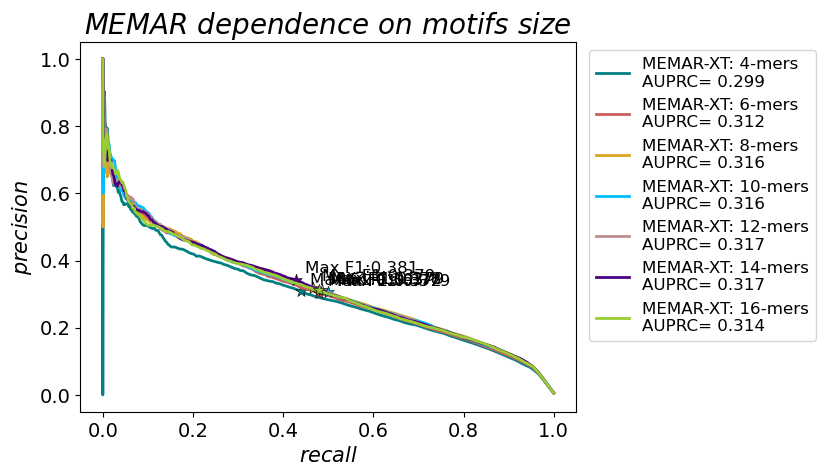

In [39]:
close("all")
_,_=plot_PR_score(vcat(score_met_ps_ds_pm4...), vcat(score_not_met_ps_ds_pm4...),  "teal","MEMAR-XT: 4-mers"; xx=0.02,pas=0.005, ls="-", mark="*");
_,_=plot_PR_score(vcat(score_met_ps_ds_pm6...), vcat(score_not_met_ps_ds_pm6...),  "indianred","MEMAR-XT: 6-mers"; xx=0.02,pas=0.005, ls="-", mark="*");
_,_=plot_PR_score(vcat(score_met_ps_ds_pm...), vcat(score_not_met_ps_ds_pm...),  "goldenrod","MEMAR-XT: 8-mers"; xx=0.02,pas=0.005, ls="-", mark="*");
_,_=plot_PR_score(vcat(score_met_ps_ds_pm10...), vcat(score_not_met_ps_ds_pm10...),  "deepskyblue","MEMAR-XT: 10-mers"; xx=0.02,pas=0.005, ls="-", mark="*");
_,_=plot_PR_score(vcat(score_met_ps_ds_pm12...), vcat(score_not_met_ps_ds_pm12...),  "rosybrown","MEMAR-XT: 12-mers"; xx=0.02,pas=0.005, ls="-", mark="*");
_,_=plot_PR_score(vcat(score_met_ps_ds_pm14...), vcat(score_not_met_ps_ds_pm14...),  "indigo","MEMAR-XT: 14-mers"; xx=0.02,pas=0.005, ls="-", mark="*");
_,_=plot_PR_score(vcat(score_met_ps_ds_pm16...), vcat(score_not_met_ps_ds_pm16...),  "yellowgreen","MEMAR-XT: 16-mers"; xx=0.02,pas=0.005, ls="-", mark="*");
legend(bbox_to_anchor=(1.5,1.0), fontsize=12)
title(L"MEMAR \ dependence \ on \ motifs \ size", size=20)
xlabel(L"recall", size=15)
xticks(fontsize=14)
yticks(fontsize=14)
ylabel(L"precision", size=15)
gcf()